
### Part A — Cleaning, KNN Classification & a Budget Decision
#### Cleaning (Q1–Q6)

1. Load the file with every column read as text first. Print shape, raw column names, and distinct values.

In [60]:
import pandas as pd
import numpy as np

df = pd.read_csv('sanjeevani_diabetes_screening_raw.csv', dtype=str)
print("Shape:", df.shape)
print("Columns:", df.columns)
print("Sex distinct:", df['Sex'].unique())
print("family_history distinct:", df['family_history'].unique())
print("HbA1c distinct:", df['HbA1c Result '].unique())

Shape: (3038, 13)
Columns: Index(['Patient ID', 'Camp Location', 'Sex', 'Age', 'family_history',
       'height_cm', 'weight_kg', 'BMI', 'waist_cm', 'Daily Steps',
       'Blood Pressure', 'total_cholesterol', 'HbA1c Result '],
      dtype='object')
Sex distinct: ['female' 'Male' 'MALE' 'Female' 'F' 'M' 'male' 'FEMALE']
family_history distinct: ['No' '0' 'Y' 'Yes' 'N' 'no' '1' 'yes']
HbA1c distinct: ['No' 'Negative' '0' 'DIABETIC' 'normal' 'Positive' '1' 'Yes']


Shape is (3038, 13)

Categories Sex, family_history, and HbA1c contain repeated inconsistant categories.

2. Standardise column names, Camp Location, and Sex.

In [61]:
df.columns = [c.strip().lower().replace(' ', '_') for c in df.columns]
df['camp_location'] = df['camp_location'].str.strip().str.title()

sex_map = {'female': 'Female', 'FEMALE': 'Female', 'Female': 'Female', 'F': 'Female',
           'Male': 'Male', 'MALE': 'Male', 'male': 'Male', 'M': 'Male'}
df['sex'] = df['sex'].str.strip().map(sex_map)

Strips whitespace, lowercases column headers, replaces spaces with underscores, and standardizes Camp Location and Sex into clean, uniform categories.

4. Convert family_history and HbA1c to 0/1, report positive share, remove exact duplicates.

In [62]:
yes_fh = {"y", "yes", "1"};  no_fh = {"n", "no", "0"}
pos_t  = {"positive", "yes", "1", "diabetic"}; neg_t = {"negative", "no", "0", "normal"}
fh = df["family_history"].str.strip().str.lower()
tg = df["hba1c_result"].str.strip().str.lower()
df["family_history"] = fh.isin(yes_fh).astype(int)
df["hba1c_result"]   = tg.isin(pos_t).astype(int)
print(f"Positive share: {df['hba1c_result'].mean():.1%}")

before = len(df)
print("exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Save the cleaned DataFrame to a CSV file
df.to_csv('sanjeevani_diabetes_screening_cleaned.csv', index=False)
print("Cleaned dataset saved as sanjeevani_diabetes_screening_cleaned.csv")

Positive share: 22.5%
exact duplicate rows: 38
Cleaned dataset saved as sanjeevani_diabetes_screening_cleaned.csv


 around 22% of visitors tested positive.

 38 exact duplicate rows were dropped

4. Split Blood Pressure into two numeric columns, systolic and diastolic. Convert Daily Steps and the other numeric columns to numbers.

In [63]:
obj = df.select_dtypes("object").columns
df[obj] = df[obj].apply(lambda s: s.str.strip())
df = df.replace(["NA", "?", "not measured", ""], np.nan)

bp = df["blood_pressure"].str.split("/", expand=True)
df["systolic"]  = pd.to_numeric(bp[0], errors="coerce")
df["diastolic"] = pd.to_numeric(bp[1], errors="coerce")
df = df.drop(columns="blood_pressure")

df["daily_steps"] = pd.to_numeric(df["daily_steps"].str.replace(",", "", regex=False), errors="coerce")
for c in ["age", "height_cm", "weight_kg", "bmi", "waist_cm", "total_cholesterol"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
print(df.dtypes)
df[["systolic", "diastolic", "daily_steps"]].describe().round(1)

patient_id            object
camp_location         object
sex                   object
age                    int64
family_history         int64
height_cm            float64
weight_kg            float64
bmi                  float64
waist_cm             float64
daily_steps          float64
total_cholesterol    float64
hba1c_result           int64
systolic             float64
diastolic            float64
dtype: object


,systolic,diastolic,daily_steps
count,2975.0,2975.0,2940.0
mean,121.9,80.8,6545.9
std,14.2,10.6,3117.6
min,90.0,55.0,300.0
25%,112.0,74.0,4277.5
50%,122.0,81.0,6540.0
75%,132.0,88.0,8650.0
max,178.0,120.0,16780.0


128/84 became systolic / diastolic

6,540 became 6540.

All disguised-missing tokens (NA, ?, not measured, blank) were turned into real NaN

5. Find the heights typed in metres and convert them to centimetres. Then fill every blank BMI by computing weight_kg / (height_m)². Show three rows before and after. Why is computing BMI better here than imputing it with the median?

In [64]:
m = df["height_cm"] < 3
print("rows typed in metres:", m.sum())
show = ["patient_id", "height_cm", "weight_kg", "bmi"]
print("\nBEFORE (height):"); print(df.loc[m, show].head(3))
df.loc[m, "height_cm"] = (df.loc[m, "height_cm"] * 100).round(1)
print("AFTER (height):");  print(df.loc[m, show].head(3))
print("height range now:", df["height_cm"].min(), "-", df["height_cm"].max())

calc = df["weight_kg"] / (df["height_cm"] / 100) ** 2
print("\nmean |recorded BMI - computed BMI| =", (df["bmi"] - calc).abs().mean().round(3))

mb = df["bmi"].isna()
print("blank BMI:", mb.sum())
print("\nBEFORE (BMI):"); print(df.loc[mb, show].head(3))
df.loc[mb, "bmi"] = calc[mb].round(1)
print("AFTER (BMI):");  print(df.loc[mb, show].head(3))
print("BMI still missing:", df["bmi"].isna().sum())

rows typed in metres: 45

BEFORE (height):
    patient_id  height_cm  weight_kg  bmi
63    SD-21552       1.56       44.3  NaN
168   SD-22591       1.65       61.1  NaN
177   SD-21600       1.61       75.4  NaN
AFTER (height):
    patient_id  height_cm  weight_kg  bmi
63    SD-21552      156.0       44.3  NaN
168   SD-22591      165.0       61.1  NaN
177   SD-21600      161.0       75.4  NaN
height range now: 135.0 - 193.0

mean |recorded BMI - computed BMI| = 0.082
blank BMI: 320

BEFORE (BMI):
   patient_id  height_cm  weight_kg  bmi
56   SD-22241      177.0       69.9  NaN
63   SD-21552      156.0       44.3  NaN
73   SD-22406      166.0       67.3  NaN
AFTER (BMI):
   patient_id  height_cm  weight_kg   bmi
56   SD-22241      177.0       69.9  22.3
63   SD-21552      156.0       44.3  18.2
73   SD-22406      166.0       67.3  24.4
BMI still missing: 0


 45 heights such as 1.56 were multiplied by 100  156.0 cm. The 320 blank BMIs were filled with it.

BMI Computing gives each person their true value; a median (~25) would give a 44 kg person and a 100 kg person the same BMI, hide the strongest diabetes signal


6. Treat impossible ages as missing. Report missing values per column. Do NOT fill them yet — say which imputation you will use inside your model pipeline and why imputing before the train/test split would leak information.

In [65]:
print("age value counts at the extremes:"); print(df["age"].sort_values().head(8).tolist(), df["age"].sort_values().tail(8).tolist())
bad = (df["age"] < 18) | (df["age"] > 100)       # camps screen adults
print("impossible ages:", bad.sum(), sorted(int(a) for a in df.loc[bad, "age"].unique()))
df.loc[bad, "age"] = np.nan
miss = df.isna().sum().to_frame("missing"); miss["pct"] = (miss["missing"] / len(df) * 100).round(1)
miss[miss.missing > 0]



age value counts at the extremes:
[0, 3, 3, 21, 21, 21, 21, 21] [80, 80, 80, 80, 140, 140, 140, 999]
impossible ages: 7 [0, 3, 140, 999]


,missing,pct
age,7,0.2
waist_cm,90,3.0
daily_steps,60,2.0
total_cholesterol,150,5.0
systolic,25,0.8
diastolic,25,0.8


7 rows had ages 0, 3, 140 or 999 and are now NaN  

missing values in age 7 (.2%) cholesterol 150 (5%), waist 90 (3%), steps 60 (2%), BP 25

can use SimpleImputer(strategy="median") inside the Pipeline

 if we imputed before splitting, the median would be computed using test rows, so test information would shape the training data and the test score would be optimistically biased. In a Pipeline the median is learned from the training fold only.

### KNN by hand (Q7–Q9)

7. A new visitor has a waist of 98 cm and walks 6,000 steps a day. Here are six past visitors:

Visitor · Waist (cm) · Daily steps · HbA1c result

P1 · 76 · 6,050 · Negative

P2 · 80 · 5,980 · Negative

P3 · 101 · 7,400 · Positive

P4 · 96 · 8,000 · Positive

P5 · 106 · 4,500 · Positive

P6 · 82 · 6,100 · Negative

Using the raw numbers, compute the Euclidean distance from the new visitor to each of P1–P6 (show the working for at least two). With k = 3, which neighbours win and what is the prediction?

* **P1** (76, 6,050): $\sqrt{(76-98)^2+(6050-6000)^2}=\sqrt{484+2500}=\sqrt{2984}=\mathbf{54.63}$
* **P2** (80, 5,980): $\sqrt{(80-98)^2+(5980-6000)^2}=\sqrt{324+400}=\sqrt{724}=\mathbf{26.91}$
* **P3** (101, 7,400): $\sqrt{(101-98)^2+(7400-6000)^2}=\sqrt{1\,960\,009}=\mathbf{1400.00}$

* **P4** (96, 8,000): $\sqrt{(96-98)^2+(8000-6000)^2}=\mathbf{2000.00}$



for k = 3  P1, P2, P6 is all Negative and prediction is Negative.

In [66]:
new = np.array([98, 6000])
past = pd.DataFrame({"visitor": ["P1","P2","P3","P4","P5","P6"],
                     "waist": [76, 80, 101, 96, 106, 82],
                     "steps": [6050, 5980, 7400, 8000, 4500, 6100],
                     "result": ["Neg","Neg","Pos","Pos","Pos","Neg"]})
X7 = past[["waist", "steps"]].to_numpy(float)
past["euclid_raw"] = np.sqrt(((X7 - new) ** 2).sum(axis=1)).round(2)
print(past)
print("k=3 neighbours:", past.nsmallest(3, "euclid_raw")["visitor"].tolist(),
      "->", past.nsmallest(3, "euclid_raw")["result"].mode()[0])

  visitor  waist  steps result  euclid_raw
0      P1     76   6050    Neg       54.63
1      P2     80   5980    Neg       26.91
2      P3    101   7400    Pos     1400.00
3      P4     96   8000    Pos     2000.00
4      P5    106   4500    Pos     1500.02
5      P6     82   6100    Neg      101.27
k=3 neighbours: ['P2', 'P1', 'P6'] -> Neg


8. Now min-max scale both features before measuring distance. Use waist range 60–140 cm and steps range 0–20,000. Recompute all six distances. With k = 3, which neighbours win now and what is the prediction? In two sentences, explain why the answer flipped — and which answer a doctor would agree with.

In [67]:
lo, hi = np.array([60, 0]), np.array([140, 20000])
sc = lambda a: (a - lo) / (hi - lo)
new_s, X8 = sc(new), sc(X7)
past["euclid_scaled"] = np.sqrt(((X8 - new_s) ** 2).sum(axis=1)).round(4)
print("scaled new visitor:", new_s)
print(past.sort_values("euclid_scaled")[["visitor","waist","steps","result","euclid_scaled"]])
n3 = past.nsmallest(3, "euclid_scaled")
print("k=3 neighbours:", n3["visitor"].tolist(), "->", n3["result"].mode()[0])

scaled new visitor: [0.475 0.3  ]
  visitor  waist  steps result  euclid_scaled
2      P3    101   7400    Pos         0.0794
3      P4     96   8000    Pos         0.1031
4      P5    106   4500    Pos         0.1250
5      P6     82   6100    Neg         0.2001
1      P2     80   5980    Neg         0.2250
0      P1     76   6050    Neg         0.2750
k=3 neighbours: ['P3', 'P4', 'P5'] -> Pos


 Scaled value  =(x-min)/(max-min)

 New visitor: waist  =(98-60)/80=0.475

 steps=6000/20000=0.300

Before scaling: A 1,400-step difference appeared more larger than a 22 cm waist difference, so waist was ignored. After scaling: Both features range 0-1, so the waist gap now matters.

9. For the same new visitor and scaled features, compute the Manhattan distance to all six. Does the k = 3 prediction change? When would you prefer Manhattan over Euclidean?

In [68]:
past["manhattan_scaled"] = np.abs(X8 - new_s).sum(axis=1).round(4)
print(past.sort_values("manhattan_scaled")[["visitor","result","manhattan_scaled"]])
n3 = past.nsmallest(3, "manhattan_scaled")
print("k=3 neighbours:", n3["visitor"].tolist(), "->", n3["result"].mode()[0])

  visitor result  manhattan_scaled
2      P3    Pos            0.1075
3      P4    Pos            0.1250
4      P5    Pos            0.1750
5      P6    Neg            0.2050
1      P2    Neg            0.2260
0      P1    Neg            0.2775
k=3 neighbours: ['P3', 'P4', 'P5'] -> Pos


 The three nearest are still P3, P4, P5 are Positive, the prediction does not change here.

Manhattan is prefered over Euclidean when data has many features, outliers, or when we do not want one large gap to dominate because it adds absolute differences instead of squaring them, so it is less sensitive to a single extreme feature.

### Building the model (Q10–Q17)

10. Split the cleaned data 75/25 into train and test, stratified on the HbA1c result, random_state = 42. Report the positive rate in each split, and the accuracy of a "predict everyone is negative" baseline on the test set.

In [69]:
from sklearn.model_selection import train_test_split
RS = 42

NUM = ["age", "bmi", "waist_cm", "daily_steps", "systolic", "diastolic", "total_cholesterol"]
CAT = ["sex", "family_history"]
X, y = df[NUM + CAT], df["hba1c_result"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RS)
print("train:", X_train.shape, " test:", X_test.shape)
print(f"positive rate  full {y.mean():.3%} | train {y_train.mean():.3%} | test {y_test.mean():.3%}")
print("test positives:", y_test.sum(), "of", len(y_test))
base_acc = 1 - y_test.mean()
print(f"'Everyone negative' baseline accuracy on test: {base_acc:.3f}")

train: (2250, 9)  test: (750, 9)
positive rate  full 22.633% | train 22.622% | test 22.667%
test positives: 170 of 750
'Everyone negative' baseline accuracy on test: 0.773


 2,250 train and 750 test with matching positive rates 22.62 % and 22.67 %

 the test set has 170 diabetics.

 "predict everyone is negative" already scores 77.3 % accuracy

11. Fit KNeighborsClassifier(n_neighbors = 5) on the seven numeric features (age, bmi, waist_cm, daily_steps, systolic, diastolic, total_cholesterol) WITHOUT scaling (median imputation only). Report accuracy, precision, recall, F1 and the confusion matrix on the test set. Compare the accuracy with Q10's baseline — what do you notice?

In [70]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score)

def metrics_at(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return dict(accuracy=accuracy_score(y_true, pred), precision=precision_score(y_true, pred, zero_division=0),
                recall=recall_score(y_true, pred), f1=f1_score(y_true, pred), roc_auc=roc_auc_score(y_true, proba))

raw_knn = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("knn", KNeighborsClassifier(n_neighbors=5))])
raw_knn.fit(X_train[NUM], y_train)
p_raw = raw_knn.predict_proba(X_test[NUM])[:, 1]
m_raw = metrics_at(y_test, p_raw)
print({k: round(v, 3) for k, v in m_raw.items()}, f"| baseline accuracy {base_acc:.3f}")
print("confusion matrix [[TN FP],[FN TP]]:\n", confusion_matrix(y_test, (p_raw >= .5).astype(int)))

{'accuracy': 0.763, 'precision': 0.441, 'recall': 0.176, 'f1': 0.252, 'roc_auc': np.float64(0.656)} | baseline accuracy 0.773
confusion matrix [[TN FP],[FN TP]]:
 [[542  38]
 [140  30]]


Accuracy is 0.763 — lower than the 0.773 do-nothing baseline. Recall is only 17.6 % (30 of 170 diabetics found, 140 missed) and AUC just 0.656.

12. Repeat Q11 with a StandardScaler in the pipeline. Report both models side by side in one table. Which feature was dominating the distance in Q11, and how do you know?

In [71]:
from sklearn.preprocessing import StandardScaler

scl_knn = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("knn", KNeighborsClassifier(n_neighbors=5))])
scl_knn.fit(X_train[NUM], y_train)
p_scl = scl_knn.predict_proba(X_test[NUM])[:, 1]
m_scl = metrics_at(y_test, p_scl)
side = pd.DataFrame({"KNN raw (no scaling)": m_raw, "KNN + StandardScaler": m_scl}).round(3)
print(side)

# Which feature dominates the unscaled distance?
imp = raw_knn.named_steps["imputer"]; knn_r = raw_knn.named_steps["knn"]
Ztr = imp.transform(X_train[NUM]); Zt = imp.transform(X_test[NUM])
var_share = pd.Series(Ztr.var(axis=0) / Ztr.var(axis=0).sum(), index=NUM)       # = share of squared distance between two random people
_, idx = knn_r.kneighbors(Zt)
nb_share = pd.Series(((Zt[:, None, :] - Ztr[idx]) ** 2).mean(axis=1).sum(axis=0), index=NUM)
nb_share = nb_share / nb_share.sum()
dom = pd.DataFrame({"std": X_train[NUM].std().round(1), "share_random_pairs_%": (var_share * 100).round(2),
                    "share_within_5_neighbours_%": (nb_share * 100).round(2)}).sort_values("std", ascending=False)
print(dom)

           KNN raw (no scaling)  KNN + StandardScaler
accuracy                  0.763                 0.788
precision                 0.441                 0.552
recall                    0.176                 0.341
f1                        0.252                 0.422
roc_auc                   0.656                 0.723
                      std  share_random_pairs_%  share_within_5_neighbours_%
daily_steps        3107.2                 99.98                        50.81
total_cholesterol    37.6                  0.01                        23.01
systolic             14.1                  0.00                         8.54
age                  11.9                  0.00                         7.41
diastolic            10.7                  0.00                         5.05
waist_cm              8.1                  0.00                         4.04
bmi                   4.2                  0.00                         1.13


 Scaling lifts every metric, accuracy now beats the baseline 0.788

 Dominant feature in Q11 is daily_steps. Its standard deviation larger than the others , so it accounts for almost all  of the squared distance between two random people

13. Explain why the scaler must be fitted on the training data only. Show the pipeline code that guarantees it.

In [72]:
print("Pipeline = imputer -> scaler -> knn, fitted on TRAIN only:")
print("  scl_knn.fit(X_train[NUM], y_train) - scaler.fit sees only training rows")
print("  scl_knn.predict_proba(X_test[NUM]) - test rows are only transformed")
tr_imp = scl_knn.named_steps["imputer"].transform(X_train[NUM])
print("\nscaler mean equals train mean (after imputation):", np.allclose(scl_knn.named_steps["scaler"].mean_, tr_imp.mean(axis=0)))
leaky = StandardScaler().fit(SimpleImputer(strategy="median").fit_transform(X[NUM]))
gap = pd.Series(np.abs(scl_knn.named_steps["scaler"].mean_ - leaky.mean_), index=NUM)
print("If the scaler had been fitted on ALL rows, its learned means would shift (test rows leak in):"); print(gap.round(2).to_dict())

Pipeline = imputer -> scaler -> knn, fitted on TRAIN only:
  scl_knn.fit(X_train[NUM], y_train) - scaler.fit sees only training rows
  scl_knn.predict_proba(X_test[NUM]) - test rows are only transformed

scaler mean equals train mean (after imputation): True
If the scaler had been fitted on ALL rows, its learned means would shift (test rows leak in):
{'age': 0.02, 'bmi': 0.0, 'waist_cm': 0.12, 'daily_steps': 25.39, 'systolic': 0.17, 'diastolic': 0.06, 'total_cholesterol': 0.31}


If the scaler were fitted on all rows, test information would leak into training, inflating test scores.

Solution is Fit the scaler only on X_train. Inside a Pipeline, fit only sees X_train and predict uses those stored statistics. During cross-validation, the pipeline is re-fitted in each fold, so validation folds never leak either.

14. Using 5-fold stratified cross-validation on the training set only, plot mean ROC-AUC against k for k = 1, 3, 5 … 51. Mark the best k. Describe what happens at very small k and at very large k, using the words bias and variance.


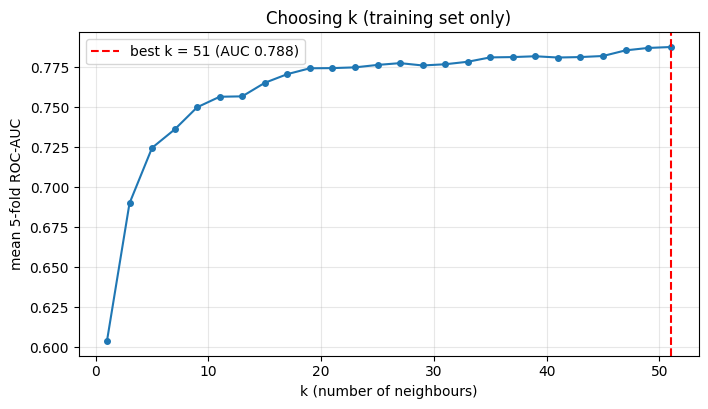

k=1: 0.604 | k=5: 0.725 | best k=51: 0.788 | k=51: 0.788


In [73]:
from sklearn.model_selection import StratifiedKFold,cross_val_score
import matplotlib.pyplot as plt

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
ks = list(range(1, 52, 2))
cv_auc = []
for k in ks:
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=k))])
    cv_auc.append(cross_val_score(pipe, X_train[NUM], y_train, cv=cv, scoring="roc_auc", n_jobs=-1).mean())
best_k = ks[int(np.argmax(cv_auc))]
plt.figure(figsize=(8, 4.2))
plt.plot(ks, cv_auc, "o-", ms=4)
plt.axvline(best_k, color="red", ls="--", label=f"best k = {best_k} (AUC {max(cv_auc):.3f})")
plt.xlabel("k (number of neighbours)"); plt.ylabel("mean 5-fold ROC-AUC"); plt.title("Choosing k (training set only)")
plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"k=1: {cv_auc[0]:.3f} | k=5: {cv_auc[2]:.3f} | best k={best_k}: {max(cv_auc):.3f} | k=51: {cv_auc[-1]:.3f}")

k = 1: CV AUC is 0.604 the model memorises noise (high variance, low bias).

k = 5: AUC climbs to 0.725 as averaging reduces variance.

Large k  predictions drift toward the 22% base rate (high bias, low variance).

k = 51: Best in range at AUC 0.788, still rising slowly at the edge.

15. Add sex and family_history with one-hot encoding (ColumnTransformer). Then run a GridSearchCV over k, weights ('uniform' vs 'distance') and p (1 = Manhattan, 2 = Euclidean), scoring ROC-AUC. Report the best combination and its CV score.

In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
prep = ColumnTransformer([("num", num_pipe, NUM),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
full = Pipeline([("prep", prep), ("knn", KNeighborsClassifier())])
grid = {"knn__n_neighbors": list(range(3, 202, 2)),
        "knn__weights": ["uniform", "distance"],
        "knn__p": [1, 2]}
gs = GridSearchCV(full, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
gs.fit(X_train, y_train)
print("best params :", gs.best_params_)
print(f"best CV AUC : {gs.best_score_:.4f}")
best = gs.best_estimator_
top = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score").head(5)[["param_knn__n_neighbors","param_knn__weights","param_knn__p","mean_test_score"]]
print("\nTop-5 combinations:"); print(top.round(4).to_string(index=False))

best params : {'knn__n_neighbors': 151, 'knn__p': 1, 'knn__weights': 'uniform'}
best CV AUC : 0.8133

Top-5 combinations:
 param_knn__n_neighbors param_knn__weights  param_knn__p  mean_test_score
                    151            uniform             1           0.8133
                    151           distance             1           0.8132
                    149            uniform             1           0.8130
                    153            uniform             1           0.8128
                    153           distance             1           0.8128


Best model: k = 151, uniform weights, Manhattan distance (p = 1) achieves CV ROC-AUC of 0.8133 up from ~0.79 without extra features.

16. Evaluate the Q15 model on the test set at the default 0.5 threshold: confusion matrix, accuracy, precision, recall, F1, and ROC-AUC. Write one plain sentence for each of the four confusion-matrix cells in camp terms (e.g. "FN = a diabetic we sent home without a test").

In [75]:
p_best = best.predict_proba(X_test)[:, 1]
pred = (p_best >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
m_best = metrics_at(y_test, p_best)
print({k: round(v, 3) for k, v in m_best.items()})
print(pd.DataFrame([[tn, fp], [fn, tp]], index=["actual Neg", "actual Pos"], columns=["pred Neg", "pred Pos"]))

{'accuracy': 0.789, 'precision': 0.8, 'recall': 0.094, 'f1': 0.168, 'roc_auc': np.float64(0.805)}
            pred Neg  pred Pos
actual Neg       576         4
actual Pos       154        16


TN = 576: non-diabetics we correctly did NOT send for the HbA1c test.

FP = 4: non-diabetics we sent for a test (a wasted Rs 450 each).

FN = 154: diabetics we sent home without a test (the costly miss).

TP = 16: diabetics we correctly sent for the test.

17. Why did we leave Camp Location out of the model? Give one argument for including it and one against.

In [76]:
print("Positive rate by camp location (train):")
print(pd.concat([df.loc[X_train.index, "camp_location"], y_train], axis=1)
        .groupby("camp_location")["hba1c_result"].agg(["mean", "count"]).round(3))

Positive rate by camp location (train):
                mean  count
camp_location              
Dombivli       0.202    391
Kharghar       0.205    381
Nerul          0.270    363
Panvel         0.217    410
Thane          0.267    341
Vashi          0.203    364


Nerul and Thane had more positive results.

But this may be because different people attended those camps. Using location could be unfair, make the model less useful at new camps, and give less importance to medical details.



### The budget decisionQ18–23

18. Look at your recall at the 0.5 threshold. In one or two sentences, explain why 0.5 is the wrong cut-off for this problem, even though it gives the highest accuracy.

At 0.5, the model catches only 16 of 170 diabetics (9.4% recall), despite 78.9% accuracy. Since missing diabetes is costlier than an extra ₹450 test.

19. For thresholds 0.1, 0.2, 0.3, 0.4 and 0.5, report in one table: tests ordered, diabetics found, diabetics missed, hit-rate (diabetics found ÷ tests), and test cost per diabetic found (₹).

In [77]:
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
    sel = p_best >= t
    found = int(y_test[sel].sum()); ordered = int(sel.sum())
    rows.append({"threshold": t, "tests_ordered": ordered, "diabetics_found": found,
                 "diabetics_missed": int(y_test.sum()) - found,
                 "hit_rate": round(found / ordered, 3) if ordered else np.nan,
                 "cost_per_diabetic_found_Rs": round(ordered * 450 / found) if found else np.nan})
thr_table = pd.DataFrame(rows); thr_table

,threshold,tests_ordered,diabetics_found,diabetics_missed,hit_rate,cost_per_diabetic_found_Rs
0,0.1,592,166,4,0.280,1605
1,0.2,333,136,34,0.408,1102
2,0.3,169,89,81,0.527,854
3,0.4,53,36,134,0.679,662
4,0.5,20,16,154,0.800,562


Lower thresholds catch more diabetics but require more tests: 0.1 orders 592 tests and misses 4, while 0.5 orders just 20 and misses 154.

20. The grant allows exactly 250 tests for the 750 people in the test set. Rank the 750 by predicted probability and send the top 250 for HbA1c. How many diabetics does that find, out of how many in total? Compare with the ≈ 55 a random choice would find.

In [78]:
def top_n(y_true, proba, n=250):
    order = np.argsort(-np.asarray(proba), kind="stable")[:n]
    return order, int(np.asarray(y_true)[order].sum())

order, found250 = top_n(y_test, p_best, 250)
total_pos = int(y_test.sum()); random_exp = y_test.mean() * 250
print(f"Top-250 by predicted probability: {found250} diabetics found out of {total_pos} "
      f"({found250/total_pos:.1%} of all diabetics, hit-rate {found250/250:.1%})")
print(f"Random 250: ~{random_exp:.0f} expected  ->  model finds {found250 - random_exp:.0f} more ({found250/random_exp:.2f}x)")
print(f"Probability at rank 250: {np.sort(p_best)[::-1][249]:.3f}; cost per diabetic found: Rs {250*450/found250:.0f}")

Top-250 by predicted probability: 118 diabetics found out of 170 (69.4% of all diabetics, hit-rate 47.2%)
Random 250: ~57 expected  ->  model finds 61 more (2.08x)
Probability at rank 250: 0.245; cost per diabetic found: Rs 953


The top 250 find 118 of 170 diabetics (69%): about 61 more than random, at roughly half the cost per case (₹953 vs. ₹1,985).

21. Compare your top-250 list with the camp's current eyeball rule, written as: test everyone aged 45+ whose waist is ≥ 90 cm (men) or ≥ 80 cm (women). How many tests does that rule need, and how many diabetics does it find? Which approach gives more diabetics per ₹?

In [79]:
male = X_test["sex"] == "Male"
rule = (X_test["age"] >= 45) & ((male & (X_test["waist_cm"] >= 90)) | (~male & (X_test["waist_cm"] >= 80)))
n_rule, f_rule = int(rule.sum()), int(y_test[rule].sum())
_, f_model_same_n = top_n(y_test, p_best, n_rule)
cmp_ = pd.DataFrame({
    "tests": [n_rule, 250, n_rule],
    "diabetics_found": [f_rule, found250, f_model_same_n],
    "hit_rate": [f_rule / n_rule, found250 / 250, f_model_same_n / n_rule],
    "Rs_per_diabetic_found": [n_rule * 450 / f_rule, 250 * 450 / found250, n_rule * 450 / f_model_same_n]},
    index=["Eyeball rule (45+, waist cut-off)", "KNN top-250", f"KNN top-{n_rule} (same tests as rule)"]).round(3)
print(cmp_)
print("\n(rows with a missing age/waist are treated as 'rule not met')")
print(f"Rule needs {n_rule} tests = Rs {n_rule*450:,}; KNN top-250 = Rs {250*450:,}")

                                   tests  diabetics_found  hit_rate  \
Eyeball rule (45+, waist cut-off)    350              118     0.337   
KNN top-250                          250              118     0.472   
KNN top-350 (same tests as rule)     350              139     0.397   

                                   Rs_per_diabetic_found  
Eyeball rule (45+, waist cut-off)               1334.746  
KNN top-250                                      953.390  
KNN top-350 (same tests as rule)                1133.094  

(rows with a missing age/waist are treated as 'rule not met')
Rule needs 350 tests = Rs 157,500; KNN top-250 = Rs 112,500


The eyeball rule finds 118 diabetics with 350 tests (₹1,57,500). The model finds the same number with 250 tests (₹1,12,500), costing about 29% less per case and staying within budget. With 350 tests, the model finds 139. Missing age or waist measurements may disadvantage the rule.

22. Pick any one test visitor your model ranks in the top 250. Print their nearest training neighbours (use kneighbors on the transformed data) with each neighbour's key measurements and HbA1c result. Write two sentences a camp volunteer could say to explain why this person is being sent for the test.

In [80]:
pos_in_test = {i: r for r, i in enumerate(order)}      # position in X_test -> rank
i = int(order[0])                                     # the visitor ranked #1
visitor = X_test.iloc[[i]]
print(f"Visitor (rank 1, predicted risk {p_best[i]:.2f}, actual result {y_test.iloc[i]}):"); print(visitor.round(1).to_string())
Z = best.named_steps["prep"].transform(visitor)
dist, idx = best.named_steps["knn"].kneighbors(Z)
nb = X_train.iloc[idx[0]].copy(); nb["hba1c"] = y_train.iloc[idx[0]].values; nb["distance"] = dist[0].round(2)
print(f"\nk = {best.named_steps['knn'].n_neighbors} neighbours used; {int(nb['hba1c'].sum())} of them were diabetic. Nearest 8:")
nb.head(8).round(1)

Visitor (rank 1, predicted risk 0.66, actual result 1):
       age   bmi  waist_cm  daily_steps  systolic  diastolic  total_cholesterol   sex  family_history
1842  69.0  33.6     113.0        590.0     140.0       87.0              243.0  Male               1

k = 151 neighbours used; 100 of them were diabetic. Nearest 8:


,age,bmi,waist_cm,daily_steps,systolic,diastolic,total_cholesterol,sex,family_history,hba1c,distance
956,55.0,31.0,112.0,2650.0,134.0,77.0,248.0,Male,1,1,4.1
2514,61.0,32.6,115.0,1480.0,150.0,89.0,222.0,Male,0,1,4.9
1904,64.0,36.6,117.0,7090.0,138.0,78.0,235.0,Male,1,1,5.0
293,66.0,34.4,119.0,3280.0,134.0,87.0,214.0,Male,0,1,5.3
503,66.0,28.0,102.0,300.0,130.0,76.0,221.0,Male,1,1,5.4
2918,59.0,25.4,103.0,2090.0,140.0,95.0,238.0,Male,1,0,5.4
1597,40.0,35.7,105.0,2970.0,128.0,91.0,241.0,Male,1,1,6.0
1944,58.0,27.4,111.0,4110.0,115.0,82.0,242.0,Male,1,1,6.1


Among visitors with measurements similar to yours, 7 of the 8 closest had diabetes. We would like to offer you one of our limited HbA1c tests today.

23. A visitor who was ranked 260th — just outside the budget — complains that a friend with "the same weight" got tested. Using what you know about how KNN measures similarity, write a short, honest reply.

In [81]:
ps = np.sort(p_best)[::-1]
print("Predicted risk at ranks 245-260:", ps[244:260].round(3).tolist())
print(f"gap between rank 250 and rank 260: {ps[249]-ps[259]:.3f}")
tied = p_best == ps[249]
print(f"{tied.sum()} visitors share exactly the rank-250 risk of {ps[249]:.3f}: {int(tied[order].sum())} of them made the 250, {int(tied.sum() - tied[order].sum())} did not")

Predicted risk at ranks 245-260: [0.245, 0.245, 0.245, 0.245, 0.245, 0.245, 0.245, 0.245, 0.245, 0.245, 0.245, 0.245, 0.245, 0.245, 0.245, 0.238]
gap between rank 250 and rank 260: 0.007
15 visitors share exactly the rank-250 risk of 0.245: 6 of them made the 250, 9 did not


I am sorry we could not test you today. The model compares your overall health profile, not just your weight. Your score was very close to the cut-off, which only reflects our limited test supply not a medical boundary.

Please follow up with a doctor, especially if you have symptoms or a family history of diabetes.

###SynthesisQ24–25

24. Summarise the raw-KNN, scaled-KNN and tuned model in one table: accuracy, recall at 0.5, ROC-AUC, and diabetics found in the top 250.

In [82]:
def summarize(name, p):
    m = metrics_at(y_test, p); _, f = top_n(y_test, p, 250)
    return {"model": name, "accuracy": m["accuracy"], "recall@0.5": m["recall"], "ROC-AUC": m["roc_auc"], "found in top-250": f}
summary = pd.DataFrame([summarize("Raw KNN (k=5, no scaling)", p_raw),
                        summarize("Scaled KNN (k=5)", p_scl),
                        summarize(f"Tuned KNN (k={gs.best_params_['knn__n_neighbors']}, {gs.best_params_['knn__weights']}, p={gs.best_params_['knn__p']}, +sex/family hx)", p_best)]).set_index("model")
summary.round(3)

,accuracy,recall@0.5,ROC-AUC,found in top-250
model,,,,
"Raw KNN (k=5, no scaling)",0.763,0.176,0.656,81
Scaled KNN (k=5),0.788,0.341,0.723,99
"Tuned KNN (k=151, uniform, p=1, +sex/family hx)",0.789,0.094,0.805,118


Each step improved ranking: AUC rose from 0.656 to 0.805, and diabetics found in the top 250 increased from 81 to 118 (about 57 by chance). Recall at 0.5 is misleading: the tuned model ranks well even though its probabilities rarely exceed 0.5.

25. Write a 5–6 sentence recommendation to the CSR programme manager: should camps use this model, how volunteers would use it on the day, how many more diabetics it finds per 250 tests than today's approach, and one risk to watch (think about who the pilot data did and didn't include).

Recommendation: Use the model to rank visitors, not diagnose them. Test the top third within the day’s budget. In testing, it found 118 of 170 diabetics with 250 tests about 34 more than the current rule, at lower cost per case ₹953 vs. ₹1,335.

It still missed about 30% of diabetics, so advise untested visitors with symptoms or high waist measurements to seek medical care. Since the pilot covered only six camps, monitor results at new locations and update the model regularly.